# What Drives Early Default? Logistic Regression on a Consumer-Finance Portfolio

**Context (simulated case study).** A Saudi consumer-finance company saw its NPL ratio double in 2025 (see the companion Power BI project).
The risk committee asks three questions:
1. Which borrower and loan characteristics are associated with **early default**, and how strongly, *holding the others constant*?
2. Did the H2-2024 growth campaign produce worse loans **even after** controlling for credit score and DBR?
3. Can a simple model rank applicants well enough to support an approval cut-off?

**Outcome definition.** `bad = 1` if the loan reached **90+ days past due or was written off within its first 12 months on book**.
**Population:** loans disbursed Jan-2023 to Dec-2024, so every loan has 12 months of observed performance by Dec-2025.

In [1]:
import json, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve

sns.set_theme(style="whitegrid", palette=["#1F4E79", "#F39C12", "#27AE60", "#C0392B"])
plt.rcParams["figure.dpi"] = 110
R = {}

## 1. Data preparation
The same cleaning rules as the Power BI model: normalise product codes and channel names, parse `dd/MM/yyyy` dates and `7.50%` text rates, deduplicate the monthly performance files.

In [2]:
loans = pd.read_csv("data/loans.csv")
loans["ProductCode"] = loans.ProductCode.str.strip().str.upper()
chan = {"mobile app": "Mobile App", "app": "Mobile App", "branch": "Branch", "broker": "Broker", "dealer": "Car Dealer",
        "car dealer": "Car Dealer", "merchant": "Merchant Partner", "merchant partner": "Merchant Partner"}
loans["Channel"] = loans.Channel.str.strip().str.lower().map(chan).fillna(loans.Channel.str.strip())
loans["ProfitRate"] = loans.ProfitRate.str.rstrip("%").astype(float) / 100
loans["DisbursementDate"] = pd.to_datetime(loans.DisbursementDate, format="%d/%m/%Y")
cust = pd.read_csv("data/customers.csv")
perf = pd.concat(pd.read_csv(f) for f in glob.glob("data/performance/*.csv")).drop_duplicates(["LoanID", "SnapshotDate"])
print(loans.shape, cust.shape, perf.shape)

(11412, 12) (11412, 8) (161984, 9)


In [3]:
early = perf[perf.MOB <= 12]
bad_ids = set(early[(early.DPD >= 90) | (early.LoanStatus == "Written-off")].LoanID)
d = loans[loans.DisbursementDate < "2025-01-01"].merge(cust[["CustomerID", "EmploymentSector", "MonthlyIncome"]], on="CustomerID")
d["bad"] = d.LoanID.isin(bad_ids).astype(int)
d["campaign_H2_2024"] = ((d.DisbursementDate >= "2024-07-01") & (d.DisbursementDate < "2025-01-01")).astype(int)
d["score_50"] = d.CreditScore / 50              # coefficients per 50 score points
d["dbr_10pp"] = d.DBR * 10                      # per 10 percentage points of DBR
d["log_principal"] = np.log(d.Principal)
R.update(population=len(d), bads=int(d.bad.sum()), bad_rate=round(d.bad.mean(), 4))
print(f"population {len(d):,} loans | bads {d.bad.sum():,} | bad rate {d.bad.mean():.2%}")

population 7,347 loans | bads 204 | bad rate 2.78%


## 2. One variable at a time
Bad rate by category with a **chi-square test of independence** and **Cramér's V** (effect size: 0.1 small, 0.3 medium, 0.5 large).

In [4]:
def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct)[0]
    return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))

d["score_band"] = pd.cut(d.CreditScore, [0, 599, 679, 749, 999], labels=["<600", "600-679", "680-749", "750+"])
d["dbr_band"] = pd.cut(d.DBR, [-1, 0.33, 0.45, 9], labels=["<=33%", "33-45%", ">45%"])
rows = []
for v in ["Channel", "ProductCode", "EmploymentSector", "score_band", "dbr_band", "campaign_H2_2024"]:
    ct = pd.crosstab(d[v], d.bad)
    rows.append([v, stats.chi2_contingency(ct)[1], cramers_v(ct)])
uni = pd.DataFrame(rows, columns=["variable", "chi2_p", "cramers_v"]).sort_values("cramers_v", ascending=False)
R["univariate"] = uni.round(4).set_index("variable").to_dict(orient="index")
uni.round(4)

,variable,chi2_p,cramers_v
2,EmploymentSector,0.0,0.1571
0,Channel,0.0,0.1461
1,ProductCode,0.0,0.1380
3,score_band,0.0,0.1253
4,dbr_band,0.0,0.1225
5,campaign_H2_2024,0.0,0.0572


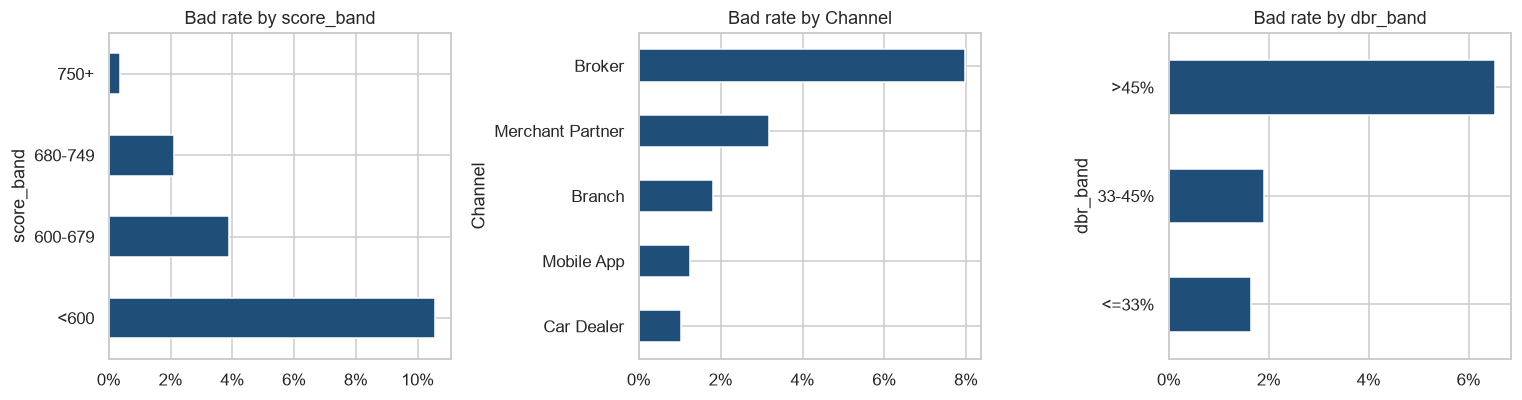

median score: bad 664 vs good 696 (Mann-Whitney p = 2.6e-18)


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, v in zip(axes, ["score_band", "Channel", "dbr_band"]):
    s = d.groupby(v, observed=True).bad.mean().sort_values() if v == "Channel" else d.groupby(v, observed=True).bad.mean()
    s.plot.barh(ax=ax, color="#1F4E79"); ax.set_title(f"Bad rate by {v}"); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
plt.tight_layout(); plt.savefig("figures/01_bad_rates.png"); plt.show()
R["bad_rate_by_score"] = d.groupby("score_band", observed=True).bad.mean().round(4).to_dict()
R["bad_rate_by_channel"] = d.groupby("Channel").bad.mean().round(4).to_dict()
u, p = stats.mannwhitneyu(d[d.bad == 1].CreditScore, d[d.bad == 0].CreditScore)
R.update(score_bad_median=float(d[d.bad == 1].CreditScore.median()), score_good_median=float(d[d.bad == 0].CreditScore.median()), score_mw_p=float(f"{p:.2e}"))
print(f"median score: bad {R['score_bad_median']:.0f} vs good {R['score_good_median']:.0f} (Mann-Whitney p = {p:.1e})")

## 3. Multicollinearity check
Variance Inflation Factor above ~5 would make individual coefficients unstable.

In [6]:
X = d[["score_50", "dbr_10pp", "log_principal", "TenorMonths", "campaign_H2_2024"]].assign(const=1)
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1] - 1)], index=X.columns[:-1]).round(2)
R["vif_max"] = float(vif.max())
vif

score_50            1.11
dbr_10pp            2.01
log_principal       2.41
TenorMonths         1.39
campaign_H2_2024    1.10
dtype: float64

## 4. Multivariable logistic regression
`SME` loans all belong to `Business` borrowers, so product and sector would be perfectly collinear. We model **sector** (with Business = SME) and **channel**, plus credit score, DBR, loan size, tenor and the campaign flag.
Coefficients are turned into **odds ratios**: OR < 1 lowers the odds of default, OR > 1 raises them.

In [7]:
train, test = train_test_split(d, test_size=0.3, random_state=42, stratify=d.bad)
formula = ("bad ~ score_50 + dbr_10pp + log_principal + TenorMonths + campaign_H2_2024"
           " + C(Channel, Treatment('Branch')) + C(EmploymentSector, Treatment('Government'))")
# inference: fit on the full population; the train/test split is only used to evaluate predictive power (section 5)
full = smf.logit(formula, data=d).fit(disp=False)
model = smf.logit(formula, data=train).fit(disp=False)
print(full.summary2().tables[0].iloc[:, :2].to_string(header=False, index=False))
orr = pd.DataFrame({"odds_ratio": np.exp(full.params), "ci_low": np.exp(full.conf_int()[0]), "ci_high": np.exp(full.conf_int()[1]),
                    "p_value": full.pvalues}).drop("Intercept")
orr.index = orr.index.str.replace(r"C\((\w+), Treatment\('[\w ]+'\)\)\[T\.", r"\1=", regex=True).str.rstrip("]")
R["odds_ratios"] = orr.round(4).to_dict(orient="index")
R["pseudo_r2"] = round(full.prsquared, 4)
orr.round(3)

             Model:            Logit
Dependent Variable:              bad
              Date: 2026-10-04 23:43
  No. Observations:             7347
          Df Model:               14
      Df Residuals:             7332
         Converged:           1.0000
    No. Iterations:           9.0000


,odds_ratio,ci_low,ci_high,p_value
Channel=Broker,4.146,2.772,6.202,0.000
Channel=Car Dealer,1.223,0.616,2.425,0.565
Channel=Merchant Partner,5.114,2.320,11.270,0.000
Channel=Mobile App,1.261,0.697,2.280,0.443
EmploymentSector=Business,7.538,3.643,15.597,0.000
EmploymentSector=Military,1.341,0.495,3.632,0.564
EmploymentSector=Private,4.109,2.455,6.879,0.000
EmploymentSector=Self-Employed,8.181,4.405,15.193,0.000
EmploymentSector=Semi-Government,1.683,0.727,3.895,0.224
score_50,0.638,0.551,0.740,0.000


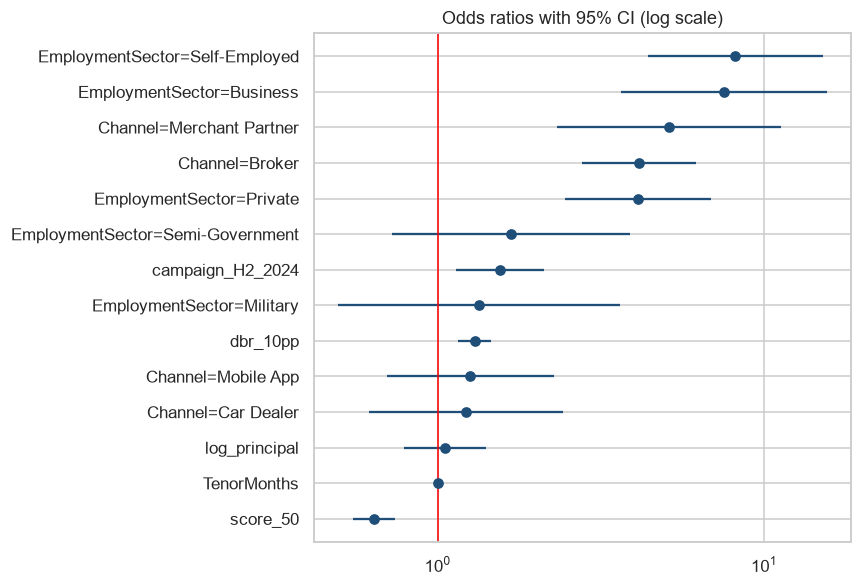

In [8]:
o = orr.sort_values("odds_ratio")
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.errorbar(o.odds_ratio, range(len(o)), xerr=[o.odds_ratio - o.ci_low, o.ci_high - o.odds_ratio], fmt="o", color="#1F4E79")
ax.axvline(1, color="red", lw=1); ax.set_yticks(range(len(o))); ax.set_yticklabels(o.index); ax.set_xscale("log")
ax.set_title("Odds ratios with 95% CI (log scale)"); plt.tight_layout(); plt.savefig("figures/02_odds_ratios.png"); plt.show()

## 5. How well does it rank risk? (hold-out test set)
Banks use **AUC / Gini** (Gini = 2·AUC − 1) and the **KS statistic**. A decile table shows how much risk is concentrated in the worst-scored applicants.

AUC 0.821 | Gini 0.643 | KS 0.505


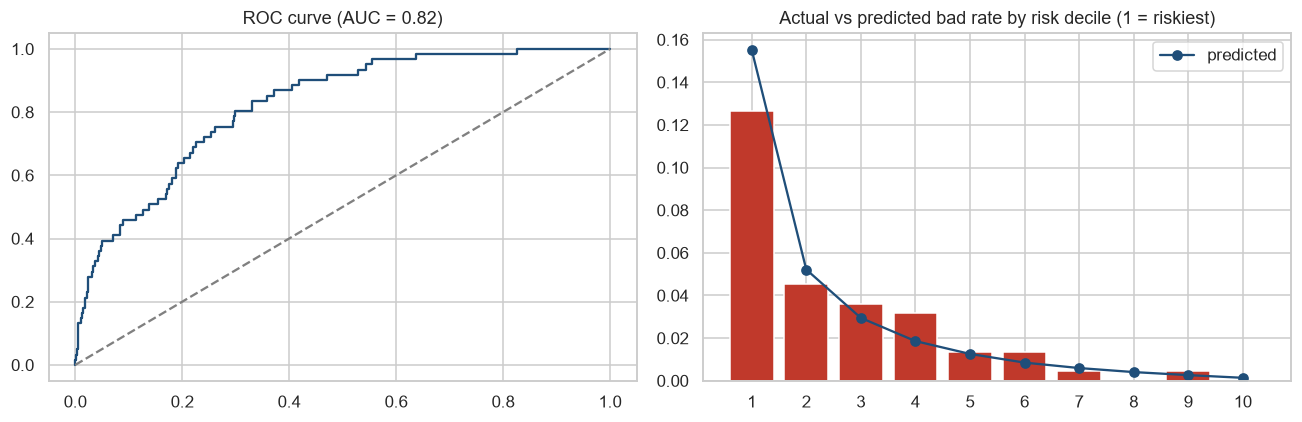

,loans,bads,avg_pd,bad_rate,cum_bad_capture
decile,,,,,
1,221,28,0.155,0.127,0.459
2,220,10,0.052,0.045,0.623
3,221,8,0.029,0.036,0.754
4,220,7,0.019,0.032,0.869
5,221,3,0.013,0.014,0.918
6,220,3,0.008,0.014,0.967
7,220,1,0.006,0.005,0.984
8,221,0,0.004,0.000,0.984
9,220,1,0.003,0.005,1.000


In [9]:
test = test.copy()
test["pd"] = model.predict(test)
auc = roc_auc_score(test.bad, test.pd)
fpr, tpr, _ = roc_curve(test.bad, test.pd)
ks = np.max(tpr - fpr)
R.update(auc=round(auc, 4), gini=round(2 * auc - 1, 4), ks=round(ks, 4))
test["decile"] = pd.qcut(test.pd.rank(method="first", ascending=False), 10, labels=range(1, 11))
dec = test.groupby("decile", observed=True).agg(loans=("bad", "size"), bads=("bad", "sum"), avg_pd=("pd", "mean"))
dec["bad_rate"] = dec.bads / dec.loans
dec["cum_bad_capture"] = dec.bads.cumsum() / dec.bads.sum()
R["top2_decile_capture"] = round(float(dec.cum_bad_capture.iloc[1]), 4)
print(f"AUC {auc:.3f} | Gini {2*auc-1:.3f} | KS {ks:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(fpr, tpr, color="#1F4E79"); ax[0].plot([0, 1], [0, 1], "--", color="grey"); ax[0].set_title(f"ROC curve (AUC = {auc:.2f})")
ax[1].bar(dec.index.astype(str), dec.bad_rate, color="#C0392B"); ax[1].plot(dec.index.astype(str), dec.avg_pd, "o-", color="#1F4E79", label="predicted")
ax[1].set_title("Actual vs predicted bad rate by risk decile (1 = riskiest)"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/03_roc_deciles.png"); plt.show()
dec.round(3)

## 6. Approval cut-off: what does each policy cost?
If we decline the riskiest X% of applicants by model score, how much does the approval rate fall and how much does the bad rate improve? We compare with the simple rule *decline credit score < 600*.

In [10]:
rows = []
for cut in [0, 0.05, 0.10, 0.15, 0.20]:
    thr = test.pd.quantile(1 - cut) if cut else 1.1
    approved = test[test.pd < thr]
    rows.append([f"model: decline worst {cut:.0%}", len(approved) / len(test), approved.bad.mean()])
rule = test[test.CreditScore >= 600]
rows.append(["rule: decline score < 600", len(rule) / len(test), rule.bad.mean()])
pol = pd.DataFrame(rows, columns=["policy", "approval_rate", "bad_rate"])
R["policies"] = pol.round(4).set_index("policy").to_dict(orient="index")
with open("results.json", "w") as f:
    json.dump(R, f, indent=1, default=float)
pol.round(4)

,policy,approval_rate,bad_rate
0,model: decline worst 0%,1.0000,0.0277
1,model: decline worst 5%,0.9497,0.0196
2,model: decline worst 10%,0.8998,0.0166
3,model: decline worst 15%,0.8499,0.0160
4,model: decline worst 20%,0.8000,0.0130
5,rule: decline score < 600,0.9583,0.0232


### Conclusions
* **Credit score and DBR** are the strongest drivers. Odds of default fall sharply with every 50 score points and rise with every 10 pp of DBR.
* **Brokers** carry much higher odds of default than branches **even with the same score and DBR**, so the problem is not just weaker applicants. Broker incentives and verification need review.
* **The H2-2024 campaign** loans default more **after controlling** for score, DBR and channel. Something besides applicant mix changed (e.g. relaxed verification), so a vintage-level review is warranted.
* The model ranks risk well (see Gini and decile capture). A score-based cut-off removes more bad loans per approval lost than a flat score floor.
* *Caveats:* observational data, so these are associations, not causal effects. The model needs monitoring and recalibration, and should be checked for fairness before production use.